Dataset 1


FIRST FIVE ROWS
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline    c

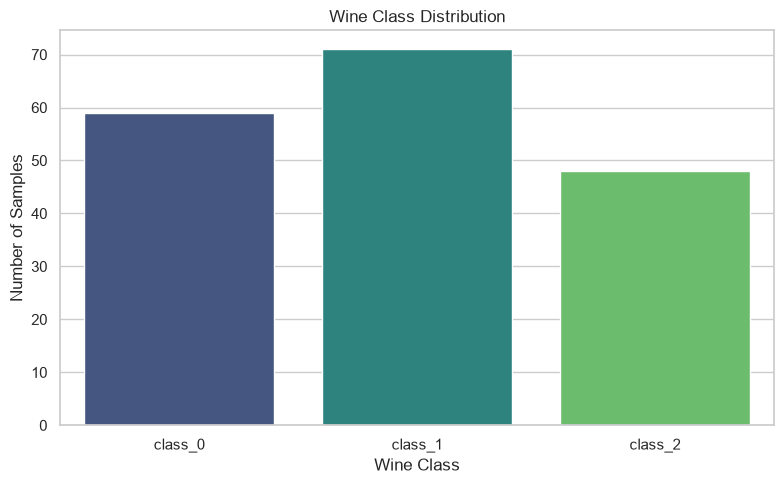

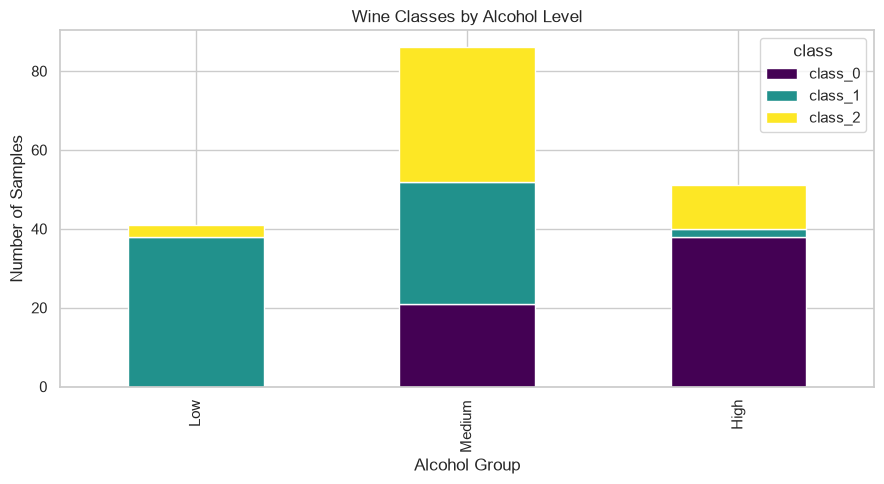

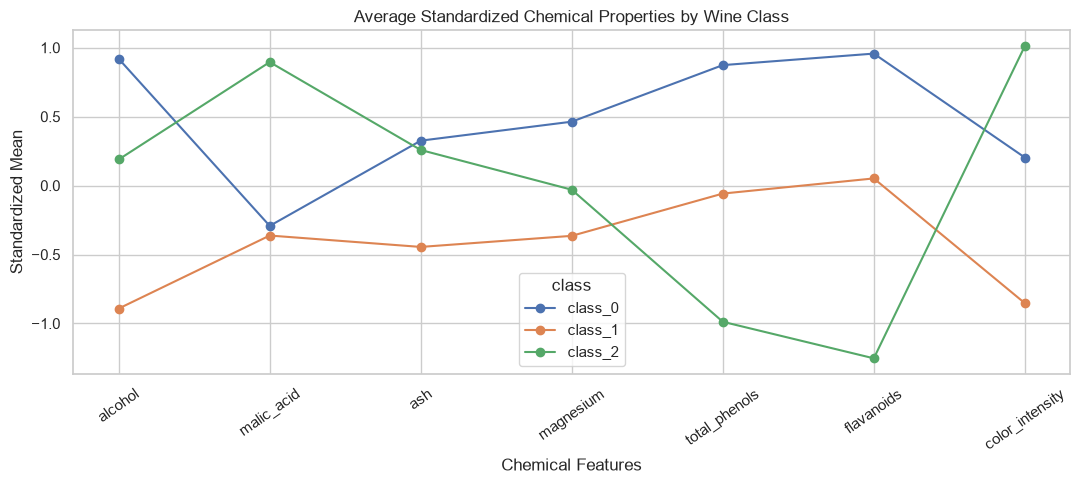

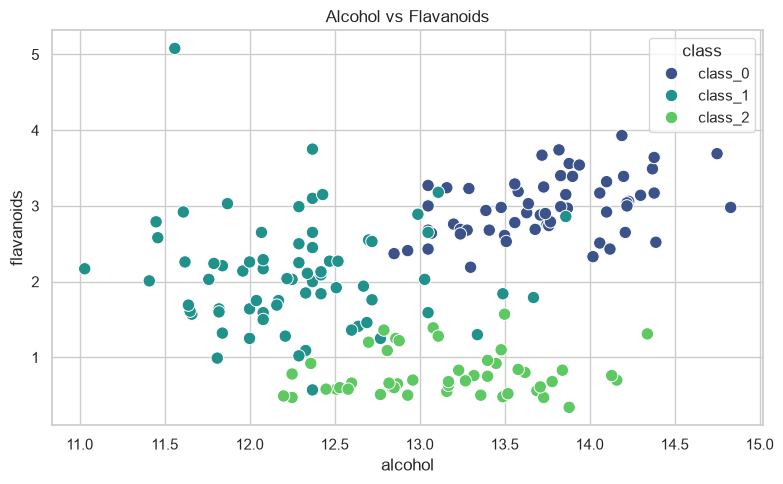

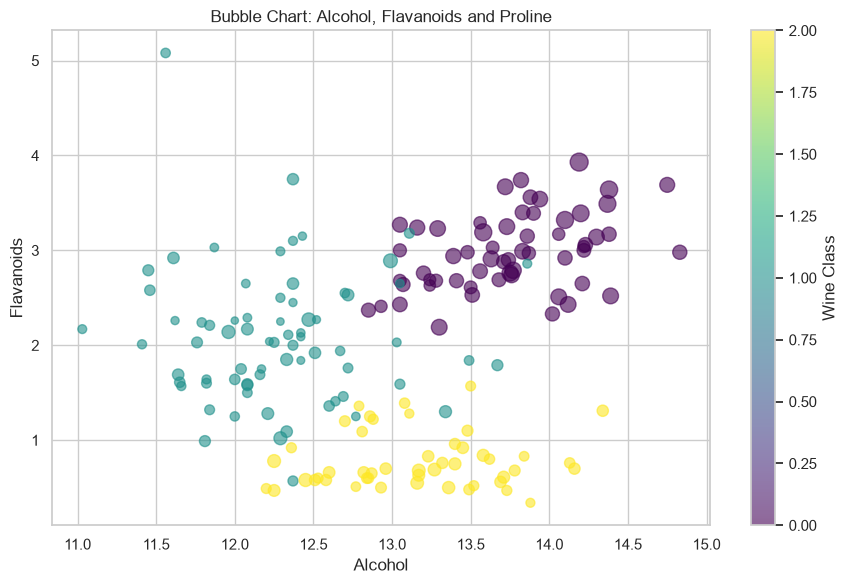

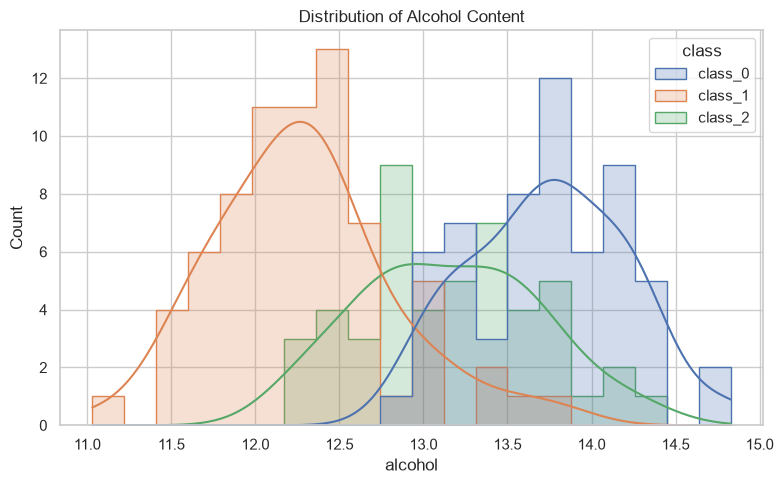

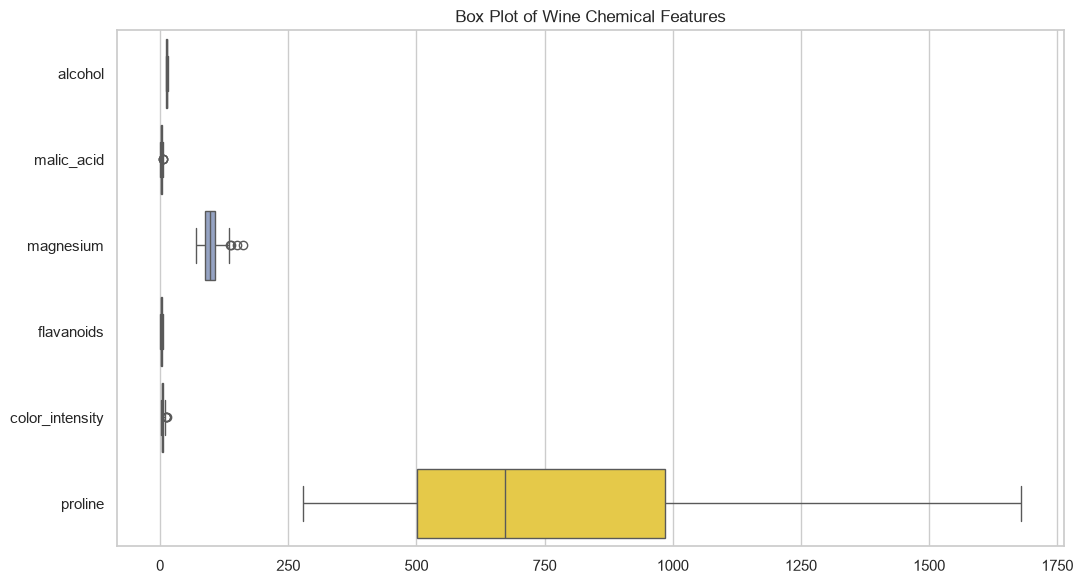

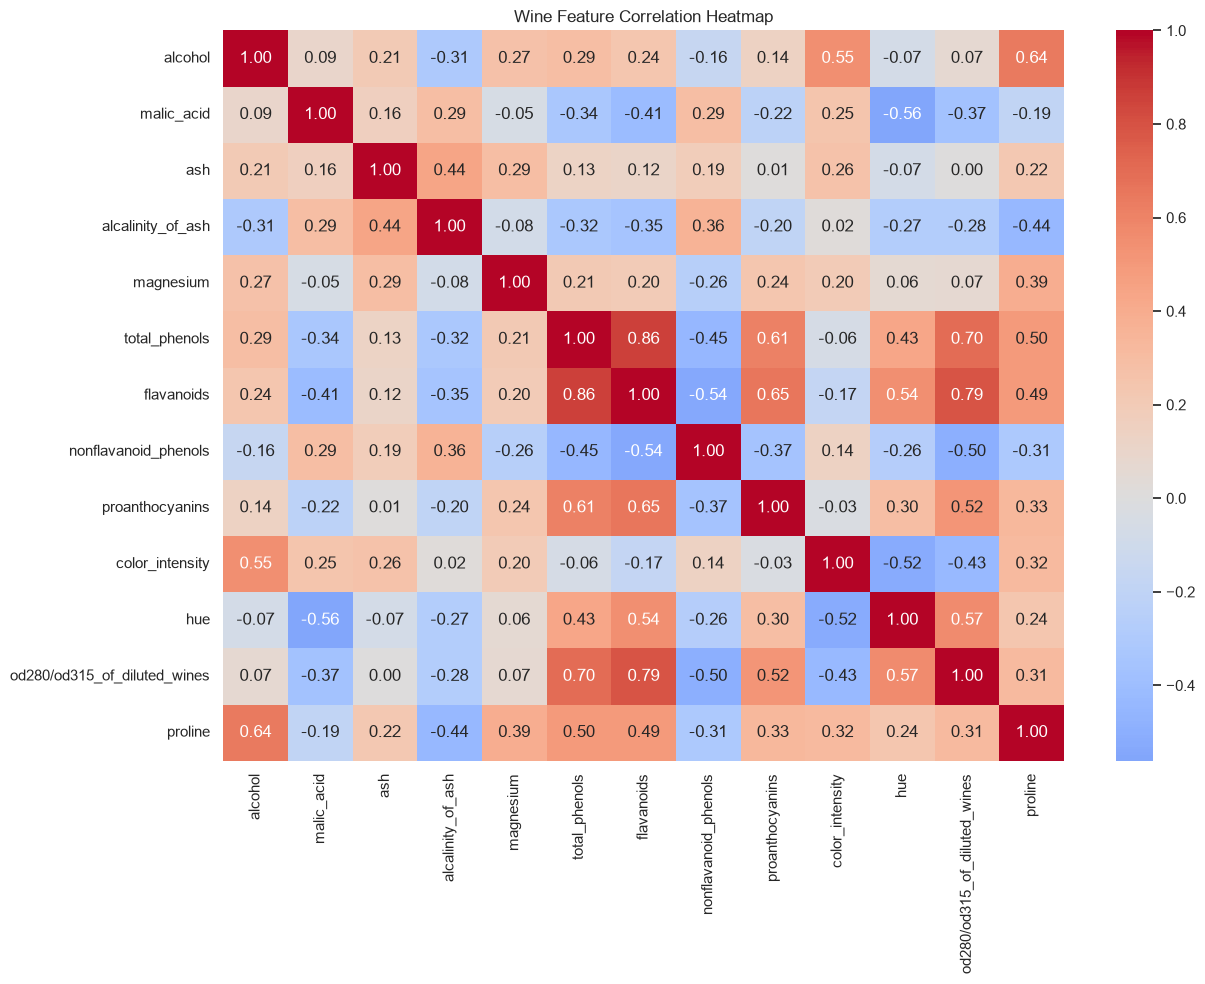

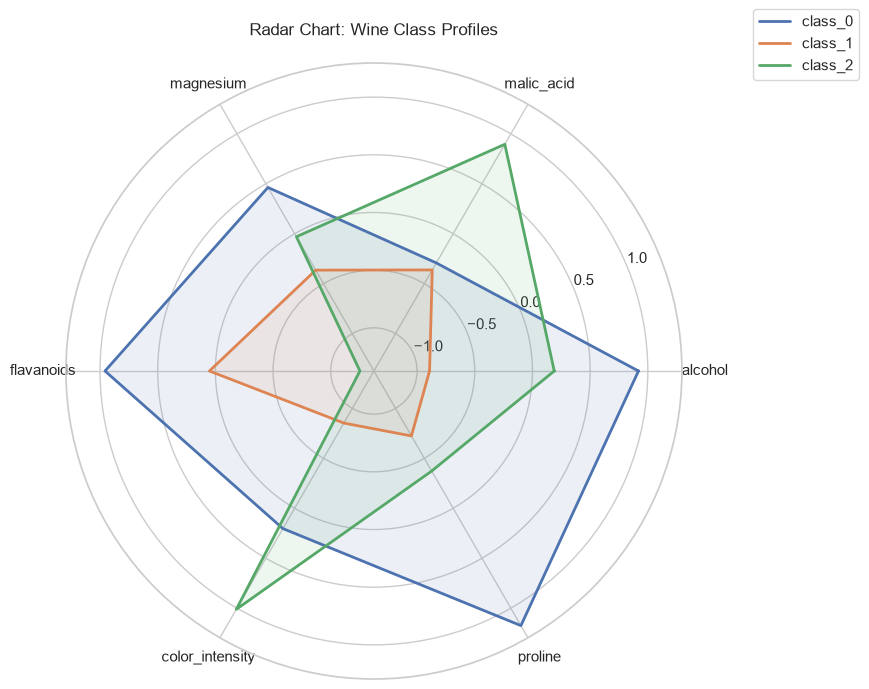

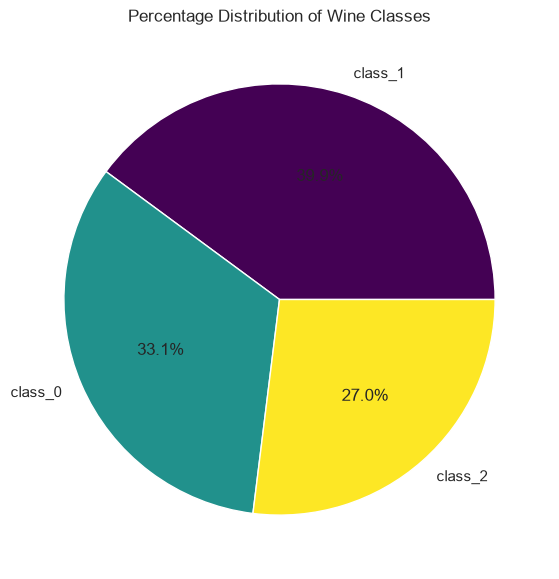

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from wordcloud import WordCloud
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

wine = load_wine(as_frame=True)
df = wine.frame.copy()

df["class"] = df["target"].map(
    dict(enumerate(wine.target_names))
)

df.drop(columns=["target"], inplace=True)

features = wine.feature_names

print("\nFIRST FIVE ROWS")
print(df.head())

print("\nDATASET INFORMATION")
print(df.info())

print("\nSTATISTICAL SUMMARY")
print(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nCLASS DISTRIBUTION")
print(df["class"].value_counts())

df[features] = df[features].fillna(
    df[features].median()
)

Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[features] < Q1 - 1.5 * IQR) |
    (df[features] > Q3 + 1.5 * IQR)
)

print("\nOUTLIER COUNT PER FEATURE")
print(outliers.sum().sort_values(ascending=False))

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="class", hue="class",
              palette="viridis", legend=False)

plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

df["alcohol_group"] = pd.cut(
    df["alcohol"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

stacked = pd.crosstab(
    df["alcohol_group"], df["class"]
)

stacked.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="viridis"
)

plt.title("Wine Classes by Alcohol Level")
plt.xlabel("Alcohol Group")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

selected = [
    "alcohol", "malic_acid", "ash",
    "magnesium", "total_phenols",
    "flavanoids", "color_intensity"
]

scaler = StandardScaler()

scaled = pd.DataFrame(
    scaler.fit_transform(df[features]),
    columns=features
)

scaled["class"] = df["class"].values

line_data = scaled.groupby("class")[selected].mean().T

line_data.plot(
    figsize=(11, 5),
    marker="o"
)

plt.title("Average Standardized Chemical Properties by Wine Class")
plt.xlabel("Chemical Features")
plt.ylabel("Standardized Mean")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="alcohol",
    y="flavanoids",
    hue="class",
    palette="viridis",
    s=80
)

plt.title("Alcohol vs Flavanoids")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))

plt.scatter(
    df["alcohol"],
    df["flavanoids"],
    s=df["proline"] / 10,
    c=df["target"] if "target" in df.columns else
      pd.Categorical(df["class"]).codes,
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("Alcohol")
plt.ylabel("Flavanoids")
plt.title("Bubble Chart: Alcohol, Flavanoids and Proline")
plt.colorbar(label="Wine Class")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="alcohol",
    hue="class",
    kde=True,
    bins=20,
    element="step"
)

plt.title("Distribution of Alcohol Content")
plt.tight_layout()
plt.show()

box_features = [
    "alcohol", "malic_acid",
    "magnesium", "flavanoids",
    "color_intensity", "proline"
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df[box_features],
    orient="h",
    palette="Set2"
)

plt.title("Box Plot of Wine Chemical Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 10))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Wine Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

radar_features = [
    "alcohol", "malic_acid",
    "magnesium", "flavanoids",
    "color_intensity", "proline"
]

radar_df = pd.DataFrame(
    scaler.fit_transform(df[radar_features]),
    columns=radar_features
)

radar_df["class"] = df["class"].values

radar_means = radar_df.groupby("class")[radar_features].mean()

angles = np.linspace(
    0, 2 * np.pi, len(radar_features), endpoint=False
).tolist()

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw={"polar": True}
)

for name, values in radar_means.iterrows():
    vals = values.tolist()
    vals += vals[:1]

    ax.plot(angles, vals, linewidth=2, label=name)
    ax.fill(angles, vals, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_features)
ax.set_title("Radar Chart: Wine Class Profiles", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

plt.show()

df["class"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    cmap="viridis"
)

plt.title("Percentage Distribution of Wine Classes")
plt.ylabel("")
plt.show()

treemap_df = df.groupby(
    ["class", "alcohol_group"],
    observed=True
).size().reset_index(name="count")

fig = px.treemap(
    treemap_df,
    path=["class", "alcohol_group"],
    values="count",
    color="count",
    color_continuous_scale="Viridis",
    title="Treemap of Wine Classes and Alcohol Groups"
)

fig.show()

word_text = """
Wine Alcohol Malic Acid Ash Magnesium
Total Phenols Flavanoids Nonflavanoid Phenols
Proanthocyanins Color Intensity Hue
OD280 Proline Wine Class Chemical Composition
Wine Quality Phenolic Compounds
"""

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="viridis"
).generate(word_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Wine Dataset Word Cloud")
plt.show()

print("\nCLASS-WISE FEATURE MEANS")
print(df.groupby("class")[features].mean().round(2))

print("\nTOP POSITIVE CORRELATIONS")

corr = df[features].corr()
corr_pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

print(corr_pairs.sort_values(ascending=False).head(10))

print("\nTOP NEGATIVE CORRELATIONS")
print(corr_pairs.sort_values().head(10))

print("\nSKEWNESS")
print(df[features].skew().sort_values(ascending=False))

print("\nMOST FREQUENT OUTLIER FEATURES")
print(outliers.sum().sort_values(ascending=False).head(5))

print("\nWINE DATASET EDA COMPLETED")

Dataset 2


FIRST FIVE ROWS
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area 

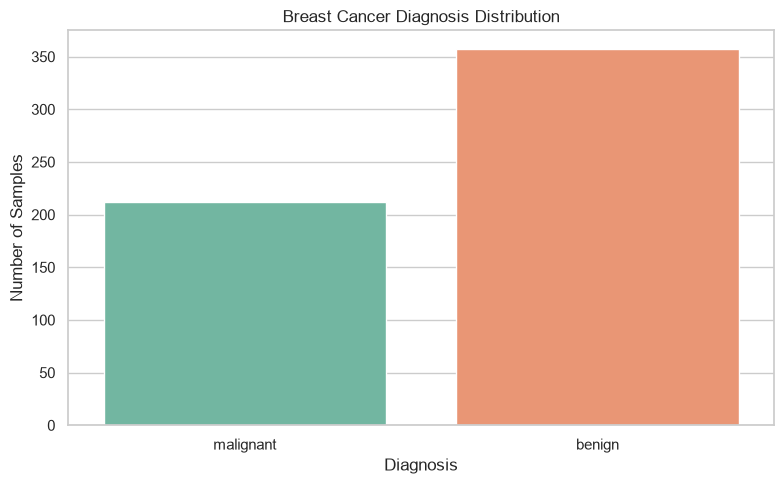

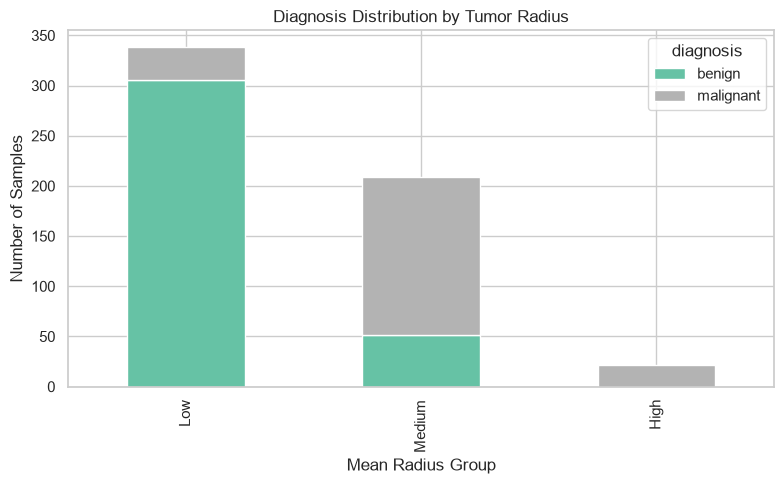

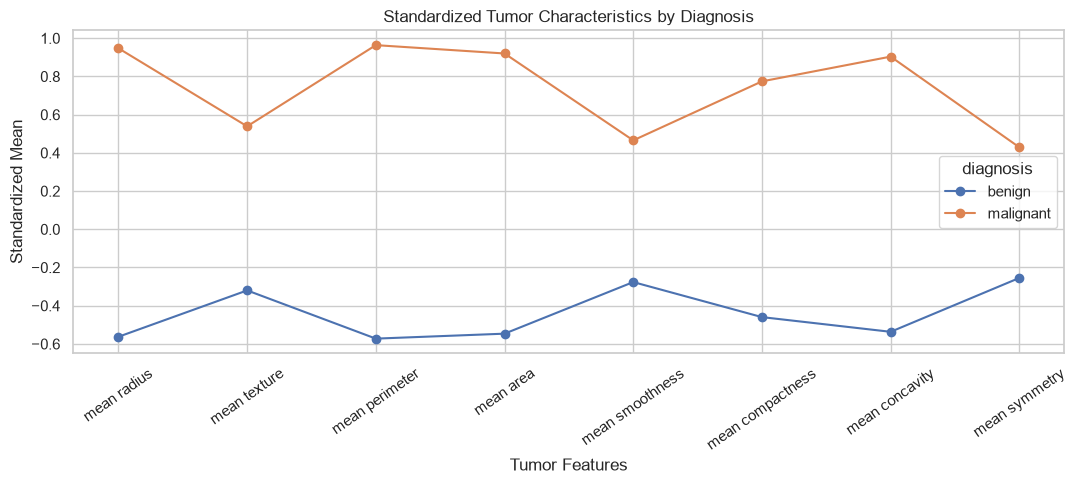

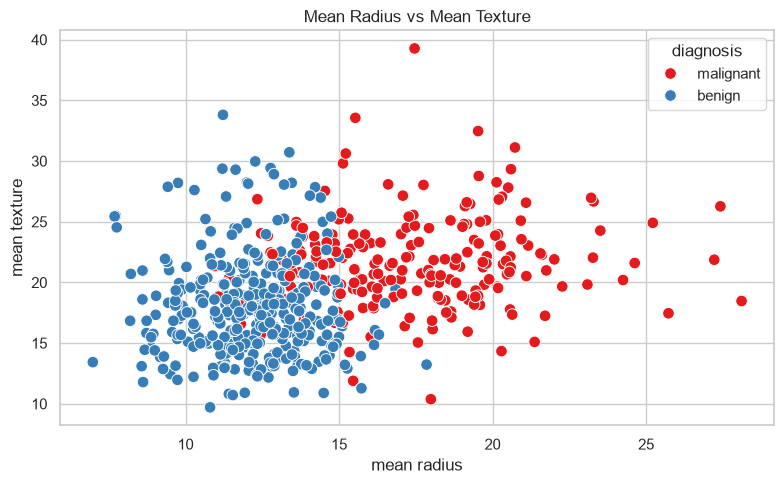

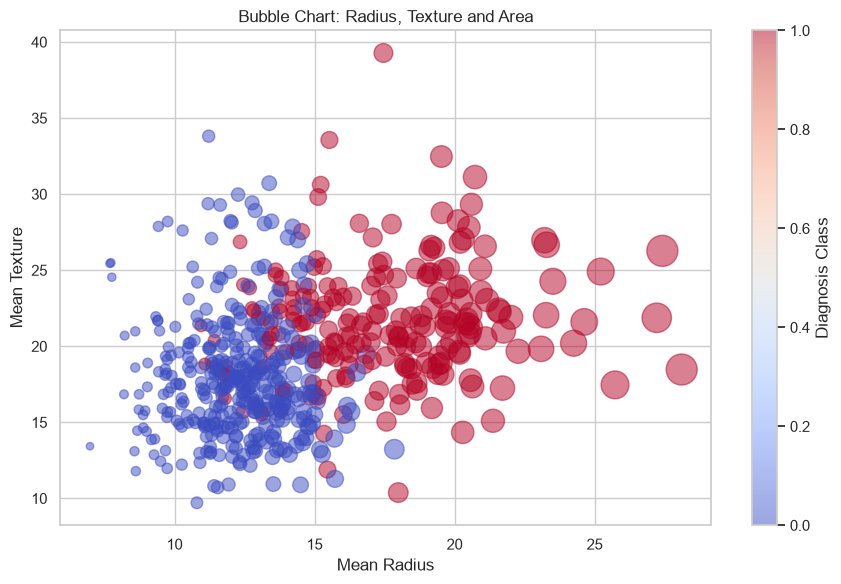

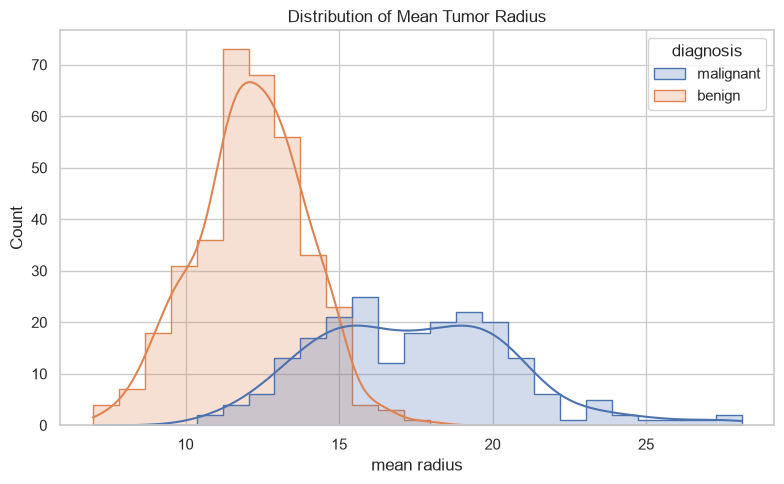

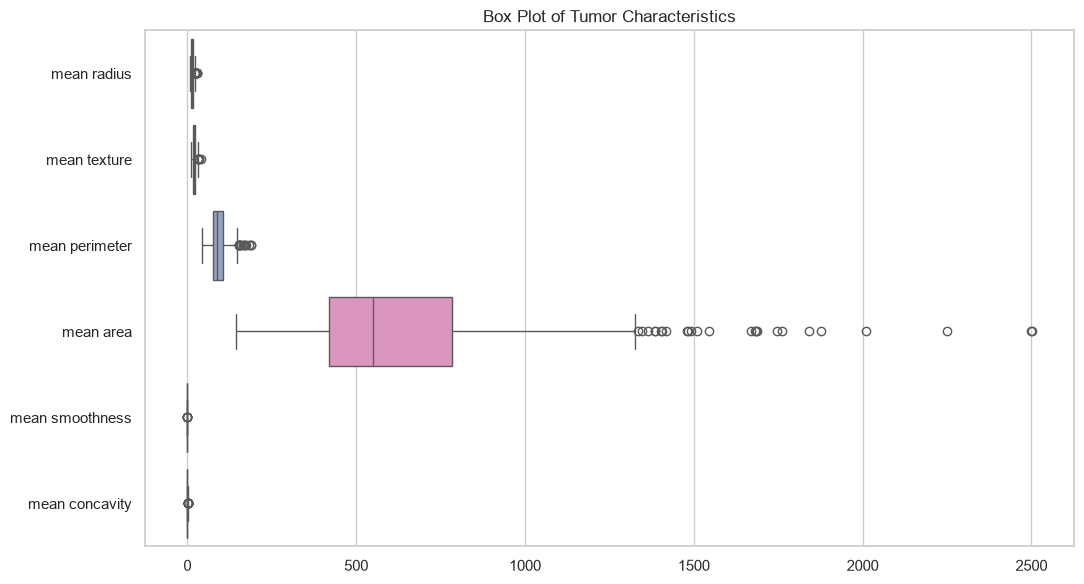

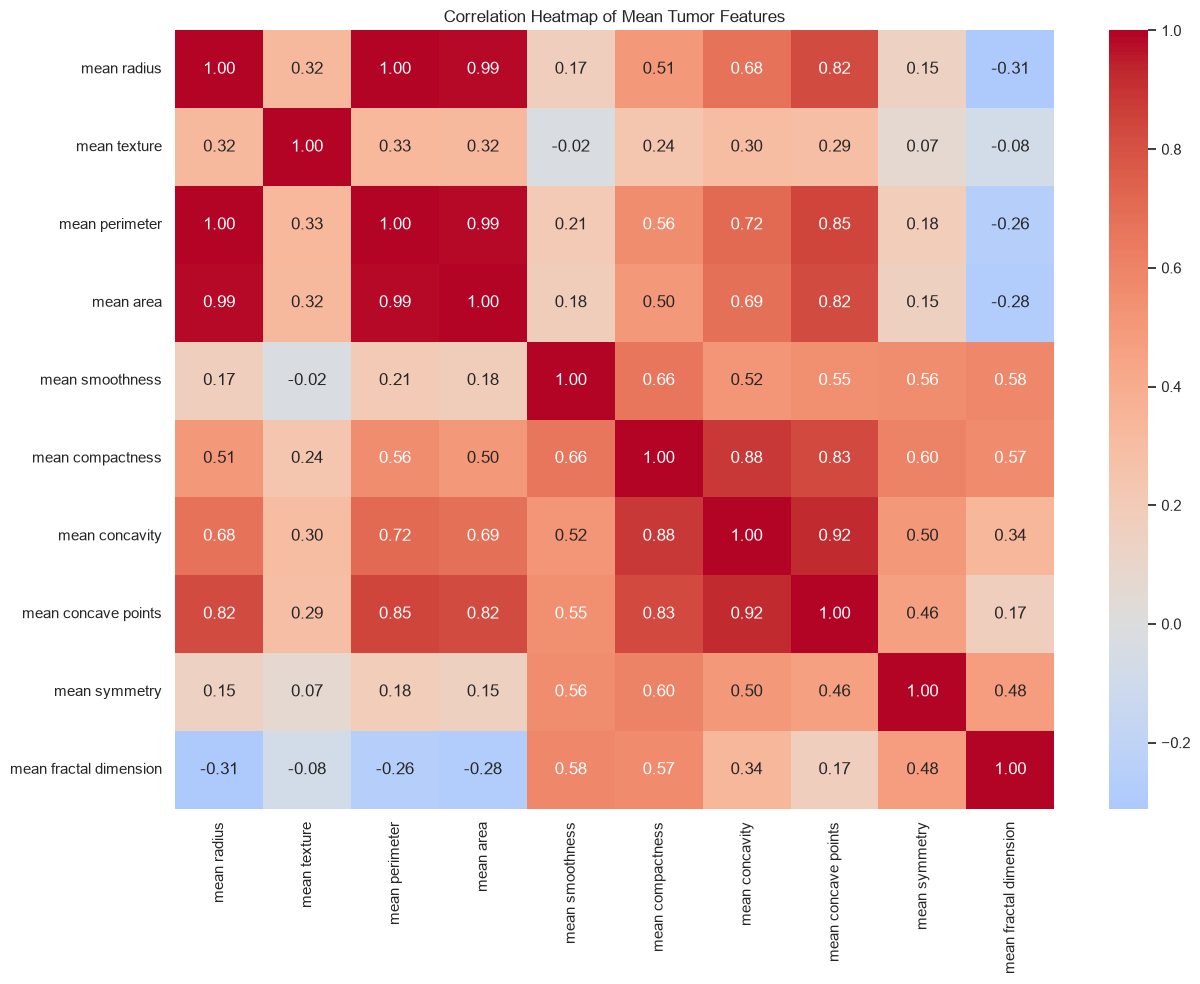

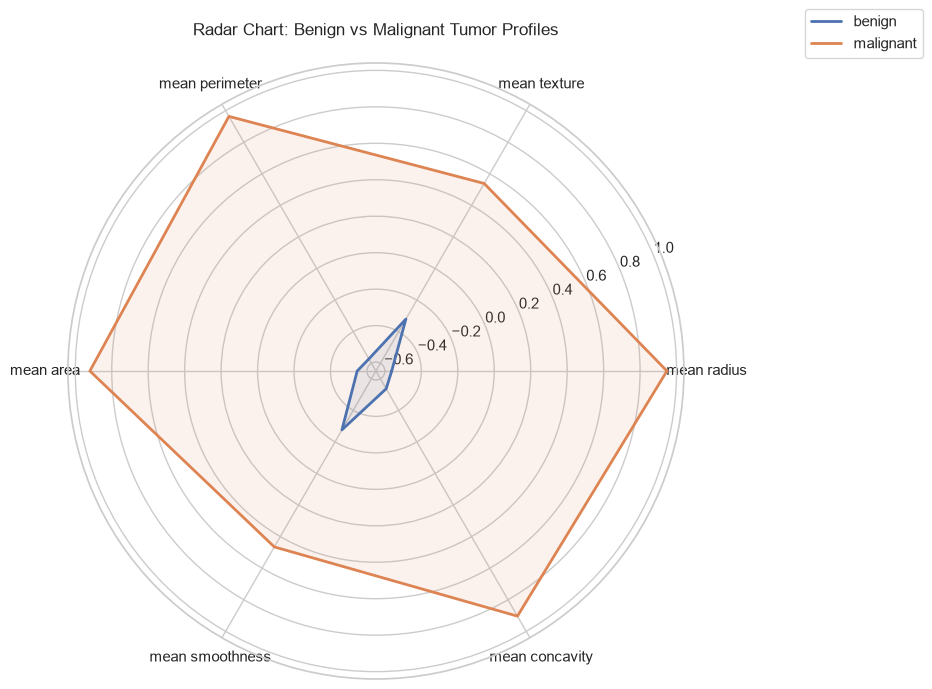

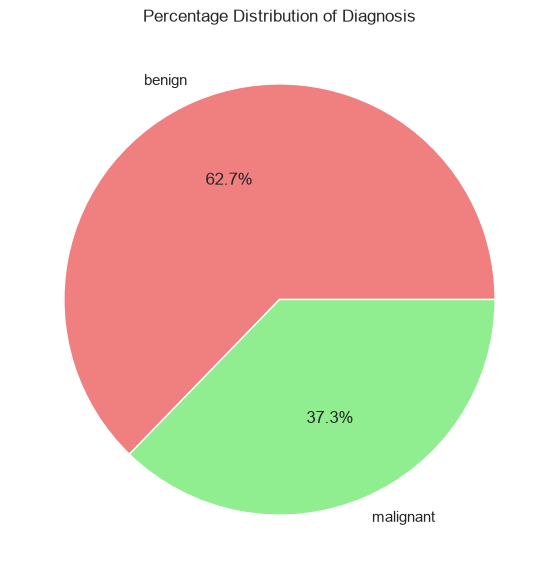

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from wordcloud import WordCloud
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

cancer = load_breast_cancer(as_frame=True)

df = cancer.frame.copy()

df["diagnosis"] = df["target"].map(
    dict(enumerate(cancer.target_names))
)

df.drop(columns=["target"], inplace=True)

features = cancer.feature_names.tolist()

print("\nFIRST FIVE ROWS")
print(df.head())

print("\nDATASET INFORMATION")
print(df.info())

print("\nSTATISTICAL SUMMARY")
print(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDIAGNOSIS DISTRIBUTION")
print(df["diagnosis"].value_counts())

df[features] = df[features].fillna(
    df[features].median()
)

Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[features] < Q1 - 1.5 * IQR) |
    (df[features] > Q3 + 1.5 * IQR)
)

print("\nOUTLIER COUNT PER FEATURE")
print(outliers.sum().sort_values(ascending=False))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

df["radius_group"] = pd.cut(
    df["mean radius"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

stacked = pd.crosstab(
    df["radius_group"],
    df["diagnosis"]
)

stacked.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    colormap="Set2"
)

plt.title("Diagnosis Distribution by Tumor Radius")
plt.xlabel("Mean Radius Group")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

selected = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean symmetry"
]

scaler = StandardScaler()

scaled = pd.DataFrame(
    scaler.fit_transform(df[features]),
    columns=features
)

scaled["diagnosis"] = df["diagnosis"].values

line_data = scaled.groupby("diagnosis")[selected].mean().T

line_data.plot(
    figsize=(11, 5),
    marker="o"
)

plt.title("Standardized Tumor Characteristics by Diagnosis")
plt.xlabel("Tumor Features")
plt.ylabel("Standardized Mean")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean texture",
    hue="diagnosis",
    palette="Set1",
    s=70
)

plt.title("Mean Radius vs Mean Texture")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))

plt.scatter(
    df["mean radius"],
    df["mean texture"],
    s=df["mean area"] / 5,
    c=pd.Categorical(df["diagnosis"]).codes,
    cmap="coolwarm",
    alpha=0.5
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Bubble Chart: Radius, Texture and Area")
plt.colorbar(label="Diagnosis Class")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="mean radius",
    hue="diagnosis",
    bins=25,
    kde=True,
    element="step"
)

plt.title("Distribution of Mean Tumor Radius")
plt.tight_layout()
plt.show()

box_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity"
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df[box_features],
    orient="h",
    palette="Set2"
)

plt.title("Box Plot of Tumor Characteristics")
plt.tight_layout()
plt.show()

mean_features = [
    f for f in features if f.startswith("mean ")
]

plt.figure(figsize=(13, 10))

sns.heatmap(
    df[mean_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Mean Tumor Features")
plt.tight_layout()
plt.show()

radar_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity"
]

radar_df = pd.DataFrame(
    scaler.fit_transform(df[radar_features]),
    columns=radar_features
)

radar_df["diagnosis"] = df["diagnosis"].values

radar_means = radar_df.groupby("diagnosis")[radar_features].mean()

angles = np.linspace(
    0, 2 * np.pi,
    len(radar_features),
    endpoint=False
).tolist()

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw={"polar": True}
)

for name, values in radar_means.iterrows():
    vals = values.tolist()
    vals += vals[:1]

    ax.plot(angles, vals, linewidth=2, label=name)
    ax.fill(angles, vals, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_features)

ax.set_title(
    "Radar Chart: Benign vs Malignant Tumor Profiles",
    pad=20
)

ax.legend(loc="upper right", bbox_to_anchor=(1.4, 1.1))

plt.show()

df["diagnosis"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    colors=["lightcoral", "lightgreen"]
)

plt.title("Percentage Distribution of Diagnosis")
plt.ylabel("")
plt.show()

treemap_df = df.groupby(
    ["diagnosis", "radius_group"],
    observed=True
).size().reset_index(name="count")

fig = px.treemap(
    treemap_df,
    path=["diagnosis", "radius_group"],
    values="count",
    color="count",
    color_continuous_scale="RdBu",
    title="Treemap of Diagnosis and Tumor Radius"
)

fig.show()

word_text = """
Breast Cancer Tumor Diagnosis
Malignant Benign Radius Texture
Perimeter Area Smoothness Compactness
Concavity Concave Points Symmetry
Fractal Dimension Mean Standard Error
Worst Measurements Cell Nuclei
Tumor Characteristics Medical Dataset
"""

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="plasma"
).generate(word_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Breast Cancer Dataset Word Cloud")
plt.show()

print("\nCLASS-WISE FEATURE MEANS")
print(df.groupby("diagnosis")[features].mean().round(2))

print("\nTOP POSITIVE CORRELATIONS")

corr = df[mean_features].corr()

corr_pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

print(corr_pairs.sort_values(ascending=False).head(10))

print("\nTOP NEGATIVE CORRELATIONS")
print(corr_pairs.sort_values().head(10))

print("\nSKEWNESS")
print(df[features].skew().sort_values(ascending=False).head(10))

print("\nMOST FREQUENT OUTLIER FEATURES")
print(outliers.sum().sort_values(ascending=False).head(10))

print("\nBREAST CANCER DATASET EDA COMPLETED")